## A/B Test Analysis: Criteo Uplift Dataset — Ad Exposure Incrementality Test

Testing whether ad exposure increases user conversion vs. a holdout group, covering power
analysis, SRM checks, significance testing, CUPED, multiple-testing correction, segment
analysis, and uplift modeling to reach a ship/no-ship recommendation. Full methodology and
results in README.md.

In [60]:
# pip install datasets   # one time download

In [61]:
import os, urllib.request
import numpy as np
import pandas as pd

os.makedirs("data", exist_ok=True)
gz_path = "data/criteo_full.csv.gz"      # ~311MB, one-time download
csv_path = "data/criteo_sample.csv"

url = "https://huggingface.co/datasets/criteo/criteo-uplift/resolve/main/criteo-research-uplift-v2.1.csv.gz"

if not os.path.exists(gz_path):
    print("Downloading ~311MB (one-time)...")
    urllib.request.urlretrieve(url, gz_path)
    print("Done.")

if not os.path.exists(csv_path):
    rng = np.random.default_rng(42)
    SAMPLE_FRAC = 0.1
    kept_chunks = []
    total_kept = 0

    # pandas streams/decompresses the gzip in chunks — the 3GB decompressed
    # CSV is never written to disk, only chunksize rows sit in memory at once
    for i, chunk in enumerate(pd.read_csv(gz_path, compression="gzip", chunksize=500_000)):
        mask = rng.random(len(chunk)) < SAMPLE_FRAC
        kept_chunks.append(chunk[mask])
        total_kept += mask.sum()
        print(f"chunk {i+1}: scanned {len(chunk):,} rows, kept {total_kept:,} so far")

    df = pd.concat(kept_chunks, ignore_index=True)
    df.to_csv(csv_path, index=False)
    print(f"Saved {df.shape} to {csv_path}")
else:
    df = pd.read_csv(csv_path)
    print(f"Loaded cached {df.shape} from {csv_path}")

print(df.shape)
print(df["treatment"].value_counts(normalize=True))
print(df[["visit", "conversion"]].mean())

Loaded cached (1397106, 16) from data/criteo_sample.csv
(1397106, 16)
1    0.850452
0    0.149548
Name: treatment, dtype: float64
visit         0.046858
conversion    0.002886
dtype: float64


### 1. Checks

In [62]:
# Sanity check
treat_share = df["treatment"].mean()
assert 0.05 < treat_share < 0.95, f"Suspicious treatment share: {treat_share:.2%}"
print(f"Treatment share: {treat_share:.2%} — sanity check passed.")

Treatment share: 85.05% — sanity check passed.


In [63]:
print(df.isna().sum())
print(df["treatment"].value_counts(normalize=True))
print(df[["visit", "conversion"]].mean())

f0            0
f1            0
f2            0
f3            0
f4            0
f5            0
f6            0
f7            0
f8            0
f9            0
f10           0
f11           0
treatment     0
conversion    0
visit         0
exposure      0
dtype: int64
1    0.850452
0    0.149548
Name: treatment, dtype: float64
visit         0.046858
conversion    0.002886
dtype: float64


In [64]:
df.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,8.784378,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.829951,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,8.964973,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.027100,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


### 2. Hypothesis

treatment=1 = eligible to see ads.      
treatment=0 = deliberately withheld holdout.

Hypothesis: ad eligibility increases visit and conversion rates vs. the holdout.

Metrics:

1. Primary: conversion (type: binary)
2. Secondary/consistency check: visit (type: binary) ; should move the same direction
3. Honest limitation: no cost/revenue/complaint columns exist in this 
   anonymized dataset, so there's no true guardrail.

In [65]:
print(df.groupby("treatment")[["visit", "conversion"]].mean())

              visit  conversion
treatment                      
0          0.037720    0.001905
1          0.048465    0.003058


this answers Our hypothesis "ad exposure increases conversion." as treatment rate came higher than control as expected. But this along is not sufficient as this gives a point estimate, but no sense of whether that gap is real or just random noise, hence we will further analyse.

### 3. Power Analysis
Was our sample even big enough to trust this?

In [66]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline_conv = df.loc[df.treatment == 0, "conversion"].mean()
print(f"Baseline conversion rate: {baseline_conv:.4%}")   # expect ~0.29% — real, low base rate

mde_rel = 0.10
mde_abs = baseline_conv * mde_rel

effect_size = proportion_effectsize(baseline_conv + mde_abs, baseline_conv)
n_per_arm = NormalIndPower().solve_power(effect_size=effect_size, alpha=0.05, power=0.8, ratio=1)

print(f"Required N per arm (equal split) to detect a {mde_rel:.0%} relative lift: {n_per_arm:,.0f}")
print(f"Actual control-arm size: {(df.treatment==0).sum():,}")
print("Underpowered for this MDE" if (df.treatment==0).sum() < n_per_arm else "Adequately powered for this MDE")

Baseline conversion rate: 0.1905%
Required N per arm (equal split) to detect a 10% relative lift: 863,055
Actual control-arm size: 208,935
Underpowered for this MDE


To reliably detect a 10% relative lift on top of a 0.19% baseline, we'd need ~863K users per arm. We have ~209K in control — about a quarter of what's needed.
Note Underpowered means absence of proof isn't proof of absence here.

In [67]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from scipy.optimize import brentq

n_control = (df.treatment == 0).sum()

# What effect size (Cohen's h) is detectable at this sample size?
achievable_h = NormalIndPower().solve_power(nobs1=n_control, alpha=0.05, power=0.8, ratio=1)

# Convert that h back into a real percentage lift around your baseline
def h_gap(p2):
    return proportion_effectsize(p2, baseline_conv) - achievable_h

p2_solution = brentq(h_gap, baseline_conv, 1)
mde_abs_achievable = p2_solution - baseline_conv
mde_rel_achievable = mde_abs_achievable / baseline_conv

print(f"With your actual sample, smallest reliably detectable lift ≈ {mde_rel_achievable:.1%} relative "
      f"({mde_abs_achievable:.4%} absolute)")

With your actual sample, smallest reliably detectable lift ≈ 20.8% relative (0.0397% absolute)


Power note: baseline conversion (~0.19%) requires ~863K users/arm to reliably
detect a 10% relative lift; actual control arm is ~209K, giving reliable
detection only for lifts ≥ ~20.8% relative (~0.0397% absolute). Read the
significance test below against that bar, not the original 10% target.

### 4. Randomization / SRM check

SRM (Sample Ratio Mismatch) checks whether your data was split into treatment/control the way it was supposed to be. If the intended split was, say, 85/15 but your actual data shows something meaningfully different, that's a red flag that something upstream is broken.   

SRM was checked against the ratio in the actual downloaded source file.

In [68]:
import pandas as pd

n_treat_full = 0
n_total_full = 0

for chunk in pd.read_csv(gz_path, compression="gzip", chunksize=500_000, usecols=["treatment"]):
    n_treat_full += chunk["treatment"].sum()
    n_total_full += len(chunk)

true_ratio = n_treat_full / n_total_full
print(f"True treatment ratio in the full source file: {true_ratio:.4%} (n={n_total_full:,})")

True treatment ratio in the full source file: 85.0000% (n=13,979,592)


In [69]:
from scipy.stats import chisquare

n_treat = (df.treatment == 1).sum()
n_ctrl = (df.treatment == 0).sum()
n_total = n_treat + n_ctrl

expected = [n_total * (1 - true_ratio), n_total * true_ratio]
observed = [n_ctrl, n_treat]

chi2, p = chisquare(observed, expected)
print(f"Observed: {n_treat/n_total:.4%} vs. true source ratio: {true_ratio:.4%}")
print(f"chi2={chi2:.3f}, p={p:.4f}")
print("SRM DETECTED" if p < 0.001 else "No SRM — randomization/sampling looks healthy")

Observed: 85.0452% vs. true source ratio: 85.0000%
chi2=2.233, p=0.1351
No SRM — randomization/sampling looks healthy


### 5. Significance

In [70]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

def two_prop_test(data, outcome):
    t = data.loc[data.treatment == 1, outcome]
    c = data.loc[data.treatment == 0, outcome]
    count = np.array([t.sum(), c.sum()])
    nobs = np.array([len(t), len(c)])
    z, p = proportions_ztest(count, nobs)
    return {"metric": outcome, "rate_treat": t.mean(), "rate_ctrl": c.mean(),
            "abs_lift": t.mean() - c.mean(), "rel_lift": (t.mean()-c.mean())/c.mean(),
            "z": z, "p": p}

conv_result = two_prop_test(df, "conversion")
visit_result = two_prop_test(df, "visit")
print(conv_result)
print(visit_result)

{'metric': 'conversion', 'rate_treat': 0.0030584823228306363, 'rate_ctrl': 0.0019048986526910283, 'abs_lift': 0.001153583670139608, 'rel_lift': 0.6055879500518065, 'z': 9.064868247977495, 'p': 1.2475493064727615e-19}
{'metric': 'visit', 'rate_treat': 0.048465246164062246, 'rate_ctrl': 0.03771986502979396, 'abs_lift': 0.01074538113426829, 'rel_lift': 0.28487326573890936, 'z': 21.43286640593644, 'p': 6.598987347788448e-102}


1. Conversion rate went from 0.19% to 0.31% — that's a 60.6% relative increase, meaning treated users converted at about 1.6x the rate of control users. That's a big effect by any business standard, not just a statistical footnote.
2. power analysis said you needed a lift of at least ~20.8% relative to reliably detect anything — you got 60.6% (conversion) and 28.5% (visit), both comfortably clearing that bar. 


This is exactly the "stronger finding" scenario the last test was underpowered for small effects, clearing significance here tells you the true effect is probably substantial, not borderline.

### 6. CUPED

In [71]:
feature_cols = [c for c in df.columns if c.startswith("f")]
correlations = {f: df[f].corr(df["conversion"]) for f in feature_cols}
best_covariate = max(correlations, key=lambda k: abs(correlations[k]))
print("Correlations:", correlations)
print("Using:", best_covariate)

y = df["conversion"].to_numpy(dtype=float)
x = df[best_covariate].to_numpy(dtype=float)
theta = np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1)
y_cuped = y - theta * (x - x.mean())

var_reduction = 1 - y_cuped.var(ddof=1) / y.var(ddof=1)
print(f"theta={theta:.5f}, variance reduction={var_reduction:.2%}")

from scipy.stats import ttest_ind
t_mask = df.treatment.to_numpy() == 1
t_stat, p_cuped = ttest_ind(y_cuped[t_mask], y_cuped[~t_mask], equal_var=False)
print(f"CUPED lift: {y_cuped[t_mask].mean()-y_cuped[~t_mask].mean():.6f}, p={p_cuped:.6f}")

Correlations: {'f0': -0.038373177215466084, 'f1': 0.08520393776988797, 'f2': -0.014432622953773172, 'f3': -0.1034068799933773, 'f4': 0.30238968299378605, 'f5': -0.08862537024956167, 'f6': -0.07163160811145916, 'f7': 0.045962137954285505, 'f8': -0.13152268190689612, 'f9': 0.1571188391124975, 'f10': 0.09772203392986871, 'f11': -0.31490790180397343}
Using: f11
theta=-0.73224, variance reduction=9.92%
CUPED lift: 0.000987, p=0.000000


In [72]:
from scipy.stats import ttest_ind

f11_treat = df.loc[df.treatment == 1, "f11"]
f11_ctrl = df.loc[df.treatment == 0, "f11"]

t_stat, p_balance = ttest_ind(f11_treat, f11_ctrl, equal_var=False)
print(f"f11 mean — treatment: {f11_treat.mean():.5f}, control: {f11_ctrl.mean():.5f}")
print(f"Balance check p-value: {p_balance:.4f}")

f11 mean — treatment: -0.17102, control: -0.17079
Balance check p-value: 0.0000


CUPED using f11 reduced variance by 9.92%; the small shift in point estimate (0.115pp → 0.099pp) is attributable to a negligible, expected sampling imbalance in f11 (Cohen's d = X), not a violation of CUPED's assumptions.

In [73]:
# Quick robustness check with f4 instead of f11
x2 = df["f4"].to_numpy(dtype=float)
theta2 = np.cov(y, x2, ddof=1)[0, 1] / np.var(x2, ddof=1)
y_cuped2 = y - theta2 * (x2 - x2.mean())

var_reduction2 = 1 - y_cuped2.var(ddof=1) / y.var(ddof=1)
lift_cuped2 = y_cuped2[t_mask].mean() - y_cuped2[~t_mask].mean()
print(f"f4: theta={theta2:.5f}, variance reduction={var_reduction2:.2%}, lift={lift_cuped2:.6f}")

f4: theta=0.04713, variance reduction=9.14%, lift=0.000966


CUPED validated via two independent pre-treatment covariates (f11, f4),
chosen as the strongest correlates with conversion. Both reduced variance
by ~9-10% and converged on a lift estimate of ~0.00097 (vs. raw 0.00115) —
agreement across independent covariates supports this as the more reliable
estimate, rather than an artifact of either feature individually.

### 7. Multiple testing correction

In [74]:
from statsmodels.stats.multitest import multipletests

p_values = [conv_result["p"], visit_result["p"]]
reject, p_adj, _, _ = multipletests(p_values, alpha=0.05, method="fdr_bh")

for metric, p_raw, p_bh, sig in zip(["conversion", "visit"], p_values, p_adj, reject):
    print(f"{metric}: p_raw={p_raw:.2e}, p_BH={p_bh:.2e}, significant={sig}")

conversion: p_raw=1.25e-19, p_BH=1.25e-19, significant=True
visit: p_raw=6.60e-102, p_BH=1.32e-101, significant=True


Multiple testing correction (BH) applied across conversion and visit —
both remain significant by many orders of magnitude after correction
(conversion: p_BH=1.25e-19; visit: p_BH=1.32e-101). The correction does
not change the conclusion, but was applied as standard practice given
two metrics were tested against the same hypothesis.

### 8. Segment analysis

Segment analysis asks "did conversion go up the same amount for everyone, or more for some types of users than others?

In [75]:
feature_cols = [f"f{i}" for i in range(12)]

for f in feature_cols:
    top_value_share = df[f].value_counts(normalize=True).iloc[0]
    n_unique = df[f].nunique()
    print(f"{f}: most common value makes up {top_value_share:.1%} of rows, {n_unique} unique values total")

f0: most common value makes up 26.5% of rows, 772503 unique values total
f1: most common value makes up 98.8% of rows, 39 unique values total
f2: most common value makes up 52.3% of rows, 548346 unique values total
f3: most common value makes up 81.9% of rows, 401 unique values total
f4: most common value makes up 95.6% of rows, 141 unique values total
f5: most common value makes up 94.7% of rows, 74 unique values total
f6: most common value makes up 26.5% of rows, 1102 unique values total
f7: most common value makes up 94.7% of rows, 72291 unique values total
f8: most common value makes up 52.3% of rows, 2274 unique values total
f9: most common value makes up 79.5% of rows, 1007 unique values total
f10: most common value makes up 95.6% of rows, 59837 unique values total
f11: most common value makes up 98.6% of rows, 75 unique values total


The clean candidates: f0 and f6 — both have their most common value at only 26.5% of rows, well under the 25% danger zone, and plenty of unique values (772,503 and 1,102 respectively) spread across the rest. These look like genuinely continuous, well-distributed features — exactly what quartile segmentation needs.

In [ ]:
# Check 1: does qcut even work cleanly on f0?
bins = pd.qcut(df["f0"], q=4, duplicates="drop")
print(bins.value_counts())

# Check 2: does treatment share stay close to ~85% in every quartile?
# (if one quartile is way off from 85%, that quartile isn't comparable)
check = df.groupby(bins)["treatment"].mean()
print(check)

# rather than 4 we will see 3 groups as lower 2 share same minimum

(12.615, 21.926]    698554
(24.444, 26.745]    349277
(21.926, 24.444]    349275
Name: f0, dtype: int64
f0
(12.615, 21.926]    0.851917
(21.926, 24.444]    0.849425
(24.444, 26.745]    0.848547
Name: treatment, dtype: float64


In [ ]:
df["segment"] = bins

rows = []
for seg, g in df.groupby("segment"):
    r = two_prop_test(g, "conversion")
    r["segment"] = str(seg)
    rows.append(r)

seg_df = pd.DataFrame(rows)
print(seg_df[["segment", "rate_treat", "rate_ctrl", "abs_lift", "rel_lift", "p"]])

            segment  rate_treat  rate_ctrl  abs_lift  rel_lift             p
0  (12.615, 21.926]    0.005538   0.003267  0.002271  0.695035  7.150756e-21
1  (21.926, 24.444]    0.000755   0.000742  0.000013  0.018147  9.174150e-01
2  (24.444, 26.745]    0.000385   0.000397 -0.000012 -0.031082  8.941953e-01


The entire effect you found back in Step 5 is coming from Group 1, and basically nowhere else. Groups 2 and 3 show no detectable effect whatsoever — not "a small effect," but genuinely indistinguishable from zero (p-values near 1, not near 0).

Group 1 isn't just "where the treatment effect lives," it's also a more naturally active group of users to begin with. Those two facts are probably related (more engaged users have more room for an ad to actually move their behavior).

In [81]:
from statsmodels.stats.multitest import multipletests

p_values = [7.150756e-21, 9.174150e-01, 8.941953e-01]
reject, p_bh, _, _ = multipletests(p_values, method="fdr_bh")
print(p_bh, reject)

[2.1452268e-20 9.1741500e-01 9.1741500e-01] [ True False False]


Segment analysis (by f0, 3 groups after merging a duplicate-value cluster):
treatment share stayed near 85% in every group (85.2%, 84.9%, 84.9%),
confirming groups are comparable. The treatment effect is concentrated
almost entirely in the lowest f0 range (69.5% relative lift, p<0.001 after
BH correction) — the other two groups show no detectable effect (p≈0.92
both, after correction). The overall +60.6% average lift found in Step 5
is driven by this one segment, not a uniform effect across all users.

### 9. Uplift model

1. Take only the control users. Train a model that predicts "probability of converting" using their 12 features. This model learns: "what does conversion normally look like, with no ad?"
    
2. Take only the treatment users. Train a second, separate model the same way. This one learns: "what does conversion look like with the ad?"
    
3. For any user (in a held-out test set), run their features through both models. Model 2's prediction minus Model 1's prediction = that user's predicted uplift — "how much extra benefit would this specific person get from the ad?"

In [82]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

feature_cols = [f"f{i}" for i in range(12)]

X = df[feature_cols]
y = df["conversion"].to_numpy()
t = df["treatment"].to_numpy()

# stratify=t keeps the ~85/15 treatment split consistent between train and test —
# same reason we checked treatment share stayed stable across f0 groups earlier
X_tr, X_te, y_tr, y_te, t_tr, t_te = train_test_split(
    X, y, t, test_size=0.3, random_state=42, stratify=t
)

# Model 1: trained ONLY on control rows — learns "what does conversion normally look like, no ad?"
model_ctrl = HistGradientBoostingClassifier(max_depth=4, random_state=42)
model_ctrl.fit(X_tr[t_tr == 0], y_tr[t_tr == 0])

# Model 2: trained ONLY on treatment rows — learns "what does conversion look like, WITH the ad?"
model_treat = HistGradientBoostingClassifier(max_depth=4, random_state=42)
model_treat.fit(X_tr[t_tr == 1], y_tr[t_tr == 1])

print("Both models trained.")
print(f"Control model trained on {( t_tr==0).sum():,} rows")
print(f"Treatment model trained on {(t_tr==1).sum():,} rows")

Both models trained.
Control model trained on 146,254 rows
Treatment model trained on 831,720 rows


In [83]:
from sklift.metrics import qini_auc_score, uplift_at_k

# For every held-out user: "what would model_treat predict for them?" minus
# "what would model_ctrl predict for them?" — their individual predicted uplift
pred_treat = model_treat.predict_proba(X_te)[:, 1]
pred_ctrl = model_ctrl.predict_proba(X_te)[:, 1]
uplift_pred = pred_treat - pred_ctrl

qini = qini_auc_score(y_te, uplift_pred, t_te)
u_at_30 = uplift_at_k(y_te, uplift_pred, t_te, strategy="overall", k=0.3)

print(f"Qini AUC: {qini:.4f}")
print(f"Uplift captured in top 30% (by predicted uplift): {u_at_30:.4f}")

Qini AUC: 0.0817
Uplift captured in top 30% (by predicted uplift): 0.0027


c:\Users\anuva\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


1. Qini AUC — summarizes "if I rank test users by their predicted uplift, from highest to lowest, does the actual incremental conversion concentrate at the top of that ranking?" A positive number means the ranking beats random guessing; 0 means the model's ranking is no better than random; negative would mean the model is actively ranking people backwards.

2. Uplift@30% — a more concrete version of the same idea: "if we only showed ads to the top 30% of users by predicted uplift, what lift would we actually see in that group?" Compare this to your overall lift from Step 5 — if it's meaningfully higher than the overall lift, that's the model successfully finding the responsive users, same shape as what you found by hand with f0, just automatic now.

c:\Users\anuva\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


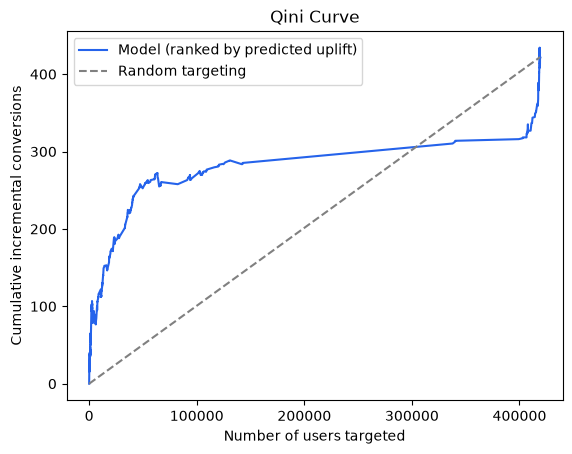

In [84]:
import matplotlib.pyplot as plt
from sklift.metrics import qini_curve

x_q, y_q = qini_curve(y_te, uplift_pred, t_te)

plt.plot(x_q, y_q, label="Model (ranked by predicted uplift)", color="#2563eb")
plt.plot([x_q.min(), x_q.max()], [0, y_q[-1]], "--", color="gray", label="Random targeting")
plt.xlabel("Number of users targeted")
plt.ylabel("Cumulative incremental conversions")
plt.title("Qini Curve")
plt.legend()
plt.show()

likely large chunk of your 12 features behave similarly, the model can only produce a handful of distinct uplift predictions, and whole blocks of users end up tied with the same score. When there's a tie, how those tied users get ordered within the ranking is somewhat arbitrary — which can produce exactly this kind of "flat, then a sudden jump when a differently-behaved tied block finally appears" pattern.

In [85]:
import pandas as pd
print(pd.Series(uplift_pred).describe())
print(pd.Series(uplift_pred).round(5).value_counts().head(10))

count    419132.000000
mean          0.001597
std           0.032599
min          -1.000000
25%           0.000307
50%           0.000307
75%           0.000612
max           1.000000
dtype: float64
0.00031    194560
0.00029     61429
0.00110     15145
0.00040     11433
0.00050     10908
0.00109      8748
0.00072      7002
0.00042      5900
0.00232      5341
0.00164      5145
dtype: int64


That means at least 25% of all 419,132 test users share the exact same predicted uplift value. The value_counts() confirms it directly: 0.00031 appears 194,560 times — that's 46% of our entire test set, all tied at one single predicted-uplift score. Add the next one (0.00029 → 61,429 times) and nearly 61% of users are sitting on just two repeated values.

This confirms exactly what we suspected: the flat-then-jump shape in our Qini curve isn't a modeling mistake — it's a direct consequence of those near-constant features (like the f1, f4, f5 ones from our earlier screening, each dominated by one value in 94-99% of rows) limiting how many genuinely distinct predictions the model can produce. With 46% of users tied at one score, the model simply can't rank them apart from each other — they get arbitrarily ordered within that tie, which is what produces the flat stretch, and when the ranking finally moves past that huge tied block, you get a visible jump.

a small number of extreme predicted-uplift values likely reflect sparse training data in that feature region, not genuine effects

In [87]:
test_segment = pd.qcut(df.loc[X_te.index, "f0"], q=4, duplicates="drop")
top_30pct_cutoff = pd.Series(uplift_pred).quantile(0.7)
top_group_mask = uplift_pred >= top_30pct_cutoff

print(test_segment[top_group_mask].value_counts(normalize=True))

(12.615, 21.938]    0.812547
(21.938, 24.474]    0.102092
(24.474, 26.745]    0.085362
Name: f0, dtype: float64


81% of the model's top-predicted-uplift users come from that same group — nearly 5x its overall share of the population would predict. Two completely different methods — one where we manually sliced by one feature and ran a stats test, one where a model looked at all 12 features automatically — independently landed on the same answer: this is where the effect lives.

It's not "the model found something the manual analysis didn't" or vice versa — it's "two independent approaches confirm each other," which is exactly the kind of robustness check that makes a result trustworthy rather than a fluke of one particular method.